In [1]:
import sys, os
sys.path.append("..")
import usf

In [6]:
usf_folders = ["O:/Nat-Tech_HGG-Projects/2025_sTEM_DollowSomalia/sTEM Profiler data/sTEM35/2025_0226/USF_Files_Dawa River Channel/",
               "O:/Nat-Tech_HGG-Projects/2025_sTEM_DollowSomalia/sTEM Profiler data/sTEM35/2025_0227/USF_Files_dawa river/",
               "O:/Nat-Tech_HGG-Projects/2025_sTEM_DollowSomalia/sTEM Profiler data/sTEM35/2025_0227/USF_Files_Juba data junction/",
               "O:/Nat-Tech_HGG-Projects/2025_sTEM_DollowSomalia/sTEM Profiler data/sTEM35/2025_0302/USF_Files_/",
               "O:/Nat-Tech_HGG-Projects/2025_sTEM_DollowSomalia/sTEM Profiler data/sTEM35/2025_0302/USF_Files_dawa river 3/",
               "O:/Nat-Tech_HGG-Projects/2025_sTEM_DollowSomalia/sTEM Profiler data/sTEM35/2025_0302/USF_Files_dawa river zone 3/",
               "O:/Nat-Tech_HGG-Projects/2025_sTEM_DollowSomalia/sTEM Profiler data/sTEM35/2025_0303/USF_Files_/",
               "O:/Nat-Tech_HGG-Projects/2025_sTEM_DollowSomalia/sTEM Profiler data/sTEM35/2025_0303/USF_Files_Dollow blue/",
               "O:/Nat-Tech_HGG-Projects/2025_sTEM_DollowSomalia/sTEM Profiler data/sTEM35/2025_0304/USF_Files_Juba 1/",
               
               #'/home/matt/geophysics_data/TEM/sTEM_data/2025_0302/USF_Files_dawa river 3/']
            ]

sweeps = []
for usf_folder in usf_folders:
    usf_files = [usf_folder+f for f in os.listdir(usf_folder) if f.endswith('.usf')]
    for usf_file in usf_files:
        with open(usf_file, 'rb') as f:
            print(f"Reading {usf_file}")
            # usf_file = f.read()     
            sweeps += usf.Sweep.from_buffer(f, combine=False)

data_overview, df_data = usf.sweep2dataframes(sweeps)

# df_data.loc[df_data['time']>1e-3, 'inuse_auto'] = False
# df_data = df_data.sort_values(by=['site_id','system_id', 'gate_id'])

Reading O:/Nat-Tech_HGG-Projects/2025_sTEM_DollowSomalia/sTEM Profiler data/sTEM35/2025_0226/USF_Files_Dawa River Channel/L001_S028_2025_0226_130536.usf
Reading O:/Nat-Tech_HGG-Projects/2025_sTEM_DollowSomalia/sTEM Profiler data/sTEM35/2025_0226/USF_Files_Dawa River Channel/L001_S011_2025_0226_120009.usf
Reading O:/Nat-Tech_HGG-Projects/2025_sTEM_DollowSomalia/sTEM Profiler data/sTEM35/2025_0226/USF_Files_Dawa River Channel/L001_S019_2025_0226_123624.usf
Reading O:/Nat-Tech_HGG-Projects/2025_sTEM_DollowSomalia/sTEM Profiler data/sTEM35/2025_0226/USF_Files_Dawa River Channel/L001_S015_2025_0226_122842.usf
Reading O:/Nat-Tech_HGG-Projects/2025_sTEM_DollowSomalia/sTEM Profiler data/sTEM35/2025_0226/USF_Files_Dawa River Channel/L001_S020_2025_0226_123851.usf
Reading O:/Nat-Tech_HGG-Projects/2025_sTEM_DollowSomalia/sTEM Profiler data/sTEM35/2025_0226/USF_Files_Dawa River Channel/L001_S005_2025_0226_114739.usf
Reading O:/Nat-Tech_HGG-Projects/2025_sTEM_DollowSomalia/sTEM Profiler data/sTEM35

c:\Users\au646858\Documents\repositories\sea-anemone\.venv\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: invalid value encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)


In [7]:
points = set([x.points for x in sweeps])

mega_sweeps = []
for pnts in points:
    mega_sweeps.append(usf.Sweep.combine_sweeps([swp for swp in sweeps if swp.points==pnts]))
lm,hm = mega_sweeps

In [8]:
df_data['include'] = df_data['inuse_auto']

In [9]:
pivot = df_data[df_data['site_id']>=0].pivot_table(
    index=['site_id'],
    columns=['sys_gate'],
    values='dbdt'
)

In [10]:
# Create pivot table with multiple values
pivot_multi = df_data[df_data['site_id']>=0].pivot_table(
    index=['site_id'],
    columns=['sys_gate'],
    values=['dbdt', 'error', 'include']
)

# Flatten the multi-level column names
pivot_multi.columns = [f'{val}_{col}' for val, col in pivot_multi.columns]
pivot_multi

,dbdt_0.0,dbdt_0.01,dbdt_0.02,dbdt_0.03,dbdt_0.04,dbdt_0.05,dbdt_1.0,dbdt_1.01,dbdt_1.02,dbdt_1.03,...,include_1.12,include_1.13,include_1.1400000000000001,include_1.15,include_1.16,include_1.17,include_1.18,include_1.19,include_1.2,include_1.21
site_id,,,,,,,,,,,,,,,,,,,,,
0,-0.000023,-9.669140e-06,-1.743570e-06,0.000002,2.745470e-06,2.442830e-06,2.507230e-06,2.596420e-06,1.960290e-06,1.302860e-06,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
1,-0.000004,3.036560e-07,1.925970e-06,0.000002,1.785770e-06,1.319300e-06,1.986810e-06,1.503150e-06,1.038760e-06,6.953560e-07,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
2,-0.000024,-1.224390e-05,-3.533860e-06,0.000001,3.134840e-06,3.138070e-06,2.556470e-06,3.210390e-06,2.601800e-06,1.765420e-06,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
3,-0.000018,-6.866230e-06,-9.107280e-08,0.000003,3.290020e-06,2.764330e-06,3.150870e-06,2.935090e-06,2.131200e-06,1.371700e-06,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
4,0.000006,4.383060e-06,2.768780e-06,0.000002,1.047280e-06,6.643290e-07,1.334890e-06,8.119620e-07,5.240690e-07,3.607120e-07,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
470,0.000004,2.615770e-06,1.695630e-06,0.000001,6.698270e-07,4.118840e-07,8.175490e-07,4.784480e-07,2.773920e-07,1.602960e-07,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
471,0.000005,3.117650e-06,2.005210e-06,0.000001,7.765840e-07,4.728290e-07,9.498530e-07,5.488890e-07,3.139150e-07,1.786540e-07,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
472,0.000005,3.065720e-06,1.916140e-06,0.000001,7.183660e-07,4.370690e-07,8.847110e-07,5.088330e-07,2.934080e-07,1.699720e-07,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [11]:
from anemone.system import Loop, Receiver, Waveform, FilterChain, ButterworthFilter
from anemone.forwards import Forward

import numpy as np

def sweep2fwr(sweeps, fwr=Forward):
    points = set(swp.points for swp in sweeps)
    forwards = []
    for pnts in points:
        swp = next(swp for swp in sweeps if swp.points == pnts)
        tx = Loop.square(swp.loop_size[0])
        rx = Receiver(x=swp.coil_location[0], y=swp.coil_location[1])
        wv = Waveform(swp.tx_ramp_time, swp.tx_ramp)
        filter_chain = []

        for f_cut, order in zip(swp.low_pass[::2], swp.low_pass[1::2]):
            filter_chain.append(ButterworthFilter(f_cut))
        fc = FilterChain(filter_chain)
        time = swp.time
        forwards.append(fwr(tx, rx, time, wv, fc, tolerance=1e-6))
    return forwards

In [12]:
import matplotlib.pyplot as plt
from anemone.inversion import *
from anemone.forwards import *
import torch

logForward = logify_forward(Forward)
fwrs = sweep2fwr(sweeps, fwr=logForward)

fwrs[0].source = fwrs[1].source
fwrs[0].receiver = fwrs[1].receiver
fwrs[0].filterfunc = fwrs[1].filterfunc

dmfwr = fwrs[0]+fwrs[1]


rho = torch.tensor([20, 10, 40])
thk = torch.tensor([30,40.])
mod_true = LogResistivity.few_layers(rho, thk)


dbdt_true = 10**dmfwr(rho, thk)

res_start = LogResistivity.smooth(torch.ones(31, dtype=torch.double)*50, torch.logspace(0, 2, 30))
fastJac = fastjacobian(Tikhonov)

In [13]:
data_overview, df_data = usf.sweep2dataframes(sweeps)

df_data['include'] = df_data['inuse_auto']

df_res = df_data.copy()
df_res['dbdt_syn'] = df_res['dbdt']*np.nan

pivot_multi = df_data[(df_data['site_id']>-1)*(df_data['gate_id']>-1)].pivot_table(
    index=['site_id'],
    columns=['sys_gate'],
    values=['dbdt', 'error', 'include'],
)
pivot_multi.columns = [f'{val}_{col}' for val, col in pivot_multi.columns]
row = pivot_multi.loc[15]

dbdt_values  = row.filter(like='dbdt_').values
error_values = row.filter(like='error_').values
include_values = row.filter(like='include_').values.astype(bool)

c:\Users\au646858\Documents\repositories\sea-anemone\.venv\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: invalid value encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)


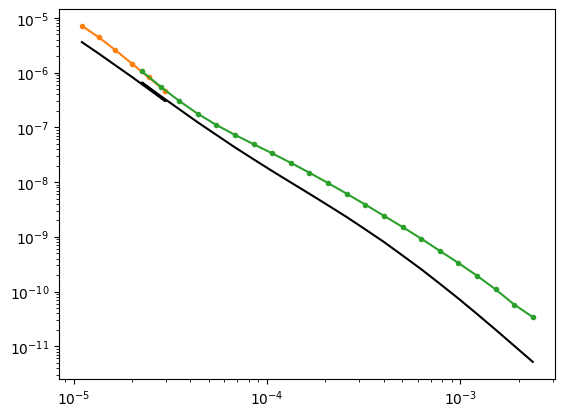

In [14]:
d_obs = torch.from_numpy(dbdt_values).abs().log10()

# d_true = 10**torch.concat([fwr(rho, thk) for fwr in fwrs])
# d_time = torch.concat([fwr.times for fwr in fwrs])

plt.figure()
plt.loglog(dmfwr.times, d_obs, 'o', label='Observed Data')
plt.plot(lm.time[14], lm.data[14], '.-')
plt.plot(hm.time[14], hm.data[14], '.-')
plt.plot(dmfwr.times, 10**dmfwr(rho,thk), 'k-', label='True Model')

In [15]:
d_obs = torch.from_numpy(dbdt_values).abs().log10()
d_err = torch.from_numpy(np.log10(1. + error_values/100.))

include_mask = include_values.astype(bool)
d_err[~include_mask] = torch.inf  # Set error to zero for included measurements

inv = fastJac(d_obs, d_err, res_start, dmfwr)
inv.data_misfit_acceptance_threshold = 1.
res_mod = inv.invert(iter_cap=10)

001	misfit:	107.28
002	misfit:	151.62
003	misfit:	217.70
004	misfit:	298.04
005	misfit:	346.22
006	misfit:	363.29
007	misfit:	361.29
008	misfit:	363.60
misfit change is less than 0.007


In [16]:
d_syn = inv.forward(*res_mod.mod)

In [17]:
d_syn

tensor([-10.0563, -10.0505, -10.0206, -10.6312, -10.7190, -10.9299, -10.5022,
        -10.8309, -11.1150, -11.3865, -11.5992, -11.8384, -12.0973, -12.3507,
        -12.6029, -12.8439, -13.1035, -13.3543, -13.6183, -13.8786, -14.1549,
        -14.4203, -14.6946, -14.9581, -15.1661, -15.2377, -15.3461, -15.3079],
       dtype=torch.float64)

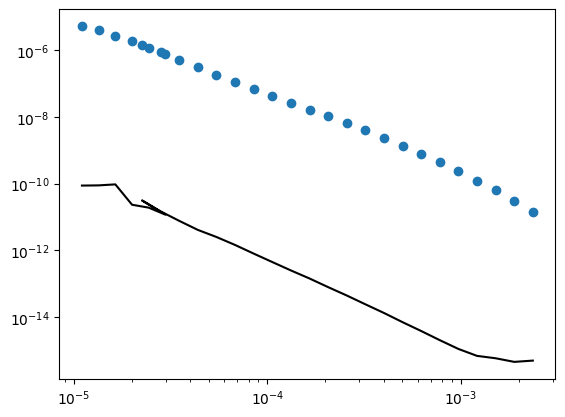

In [18]:
plt.figure()
plt.loglog(dmfwr.times, 10**d_obs, 'o', label='Observed Data')
# plt.plot(lm.time[14], lm.data[14], '.-')
# plt.plot(hm.time[14], hm.data[14], '.-')
plt.plot(dmfwr.times, 10**d_syn, 'k-', label='True Model')

In [19]:
import pandas as pd

def silence(s):
    pass

data_overview, df_data = usf.sweep2dataframes(sweeps)
df_overview = df_res.pivot_table(
    index=['site_id'],
    values=['date', 'daytime', 'latitude', 'longitude', 'elevation'],
    aggfunc='first'
)


df_data['include'] = df_data['inuse_auto']

df_res = df_data.copy()
df_res['dbdt_syn'] = df_res['dbdt']*np.nan

pivot_multi = df_data[(df_data['site_id']>-1)*(df_data['gate_id']>-1)].pivot_table(
    index=['site_id'],
    columns=['sys_gate'],
    values=['dbdt', 'error', 'include', 'data_id'],
)
pivot_multi.columns = [f'{val}_{col}' for val, col in pivot_multi.columns]

assert len(pivot_multi) == len(df_overview), "Expected 4 columns in pivot_multi"

pivot_multi.sort_values(by='site_id', inplace=True)
df_overview.sort_values(by='site_id', inplace=True)

c:\Users\au646858\Documents\repositories\sea-anemone\.venv\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: invalid value encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)


In [20]:
results = []
for i,(row,row_meta) in enumerate(zip(pivot_multi.iterrows(), df_overview.iterrows())):
    if i==1:
        print(row)
        print(row_meta)

(1, data_id_0.0     61.0
data_id_0.01    62.0
data_id_0.02    63.0
data_id_0.03    64.0
data_id_0.04    65.0
                ... 
include_1.17     1.0
include_1.18     1.0
include_1.19     1.0
include_1.2      1.0
include_1.21     1.0
Name: 1, Length: 112, dtype: float64)
(1, date         2.025023e+07
daytime      6.096670e+00
elevation    1.820000e+02
latitude     4.175332e+00
longitude    4.207927e+01
Name: 1, dtype: float64)


In [21]:
results = []
inv_list = []

for i,((id_row, row), (id_meta, row_meta)) in enumerate(zip(pivot_multi.iterrows(), df_overview.iterrows())):
    assert id_meta == id_row, "Site ID mismatch between row and metadata"

    dbdt_values  = row.filter(like='dbdt_').values
    error_values = row.filter(like='error_').values
    include_values = row.filter(like='include_').values
    data_id = row.filter(like='data_id_').values

    d_obs = torch.from_numpy(dbdt_values).abs().log10()
    d_err = torch.from_numpy(np.log10(1. + error_values/100.))
    include_mask = include_values.astype(bool)
    d_err[~include_mask] = torch.inf  # Set error to zero for included measurements

    inv = fastJac(d_obs, d_err, res_start, dmfwr, logger=silence)
    inv.smoothness_vert = 0.4
    inv.setup_matrices()
    inv_list.append(inv)
    # inv.invert(iter_cap=20)
    # print(i)
    

In [ ]:
# torch.set_num_threads(8)

import utm
utmx,utmy,zone_number,zone_letter = utm.from_latlon(df_overview['latitude'].values, df_overview['longitude'].values)
df_overview['utm_x'] = utmx
df_overview['utm_y'] = utmy
df_overview['zone_number'] = zone_number
df_overview['zone_letter'] = zone_letter

inv = SCI(inv_list, x= df_overview['utm_x'].values, y=df_overview['utm_y'].values)
inv.data_misfit_acceptance_threshold = 0.95
inv.smoothness_vert = 0.3
inv.smoothness_lat = 0.3
res_mods = inv.invert(iter_cap=10)

In [19]:
for i,((id_row, row), (id_meta, row_meta)) in enumerate(zip(pivot_multi.iterrows(), df_overview.iterrows())):
    assert id_meta == id_row, "Site ID mismatch between row and metadata"

    data_id = row.filter(like='data_id_').values    
    res_mod = res_mods[i].copy()

    d_syn = 10**inv_list[i].forward(*res_mod.mod)
    print(d_syn)
    df_res.loc[data_id, 'dbdt_syn'] = d_syn.numpy()

    rho,thick = res_mod.mod
    row_meta['site_id'] = id_meta
    row_meta['resistivity'] = rho.detach().cpu().numpy().tolist()
    row_meta['thickness'] = thick.detach().cpu().numpy().tolist()
    results.append(row_meta.to_dict())
    print(f'Inversion for data_id {i:02d} completed.')

df_resmod = pd.DataFrame(results)

tensor([6.8274e-06, 4.1457e-06, 2.5042e-06, 1.5881e-06, 1.0370e-06, 6.9846e-07,
        1.3172e-06, 8.4146e-07, 5.4595e-07, 3.4951e-07, 2.1910e-07, 1.3303e-07,
        7.9558e-08, 4.6730e-08, 2.7388e-08, 1.6095e-08, 9.4268e-09, 5.5853e-09,
        3.2522e-09, 1.9119e-09, 1.0919e-09, 6.2661e-10, 3.5014e-10, 1.9560e-10,
        1.0739e-10, 5.8626e-11, 3.1733e-11, 1.7092e-11], dtype=torch.float64)
Inversion for data_id 00 completed.
tensor([2.4175e-06, 1.7929e-06, 1.3580e-06, 1.0230e-06, 7.5571e-07, 5.4116e-07,
        9.1864e-07, 6.4384e-07, 4.3550e-07, 2.8459e-07, 1.8108e-07, 1.1213e-07,
        6.8782e-08, 4.1647e-08, 2.5162e-08, 1.5179e-08, 9.0753e-09, 5.4422e-09,
        3.1943e-09, 1.8831e-09, 1.0769e-09, 6.1800e-10, 3.4540e-10, 1.9318e-10,
        1.0636e-10, 5.8362e-11, 3.1816e-11, 1.7304e-11], dtype=torch.float64)
Inversion for data_id 01 completed.
tensor([7.3431e-06, 4.5142e-06, 2.7261e-06, 1.7195e-06, 1.1186e-06, 7.5452e-07,
        1.4224e-06, 9.0800e-07, 5.9160e-07, 3.8107e-

In [ ]:
df_res.to_csv('dollow_inversion_SCI_results.csv')

In [27]:
df_resmod
rows = []
for _, row in df_resmod.iterrows():
    site_id = row['site_id']
    resistivities = row['resistivity']
    thicknesses = row['thickness']
    # Compute top and bottom depths
    tops = np.concatenate([[0], np.cumsum(thicknesses)[:-1]])
    bottoms = np.cumsum(thicknesses)
    for i, (rho, top, bottom) in enumerate(zip(resistivities, tops, bottoms)):
        rows.append({
            'site_id': site_id,
            'daytime': row['daytime'],
            'date': row['date'],
            'latitude': row['latitude'],
            'longitude': row['longitude'],
            'elevation': row['elevation'],
            'layer': i,
            'resistivity': rho,
            'top_depth': top,
            'bottom_depth': bottom,
            'center_depth': (top + bottom) / 2
        })

df_layers = pd.DataFrame(rows)
df_layers.to_csv("dollow_inversion_SCI_results_models.csv", index=False)

In [28]:
# ...existing code...
df_layers_long = pd.melt(
    df_layers,
    id_vars=['site_id', 'daytime', 'longitude', 'latitude', 'date', 'elevation', 'layer', 'resistivity'],
    value_vars=['top_depth', 'bottom_depth'],
    var_name='depth_type',
    value_name='depth'
).sort_values(['daytime', 'layer', 'depth'])

# Optional: drop 'depth_type' if you don't need it
df_layers_long = df_layers_long.drop(columns=['depth_type'])

df_layers_long
df_layers_long['z'] = df_layers_long['elevation']-df_layers_long['depth']

In [29]:
import plotly.express as px

fig = px.line(
    df_layers_long,
    x="resistivity",
    y="z",
    color="site_id",
    # markers=True,
    labels={
        "resistivity": "Resistivity [Ω·m]",
        "center_depth": "Depth [m]",
        "site_id": "Site ID"
    },
    title="Resistivity vs. Depth by Site"
)

# Reverse y-axis so depth increases downward
# fig.update_yaxes(autorange="reversed")
fig.update_layout(
    xaxis_type="log",
)

fig.show()

In [30]:
import plotly.express as px

# Pivot the melted DataFrame
df_layers_long['log_resistivity'] = np.log10(df_layers_long['resistivity'])

heatmap_df = df_layers_long.pivot_table(
    index='depth', columns='daytime', values='log_resistivity'
)

# Sort depth so it increases downward
heatmap_df = heatmap_df.sort_index(ascending=True)

fig = px.imshow(
    heatmap_df,
    aspect='auto',
    origin='lower',
    color_continuous_scale='turbo',
    labels={'x': 'Site ID', 'y': 'Depth [m]', 'color': 'Resistivity [Ω·m]'},
    title='Resistivity Heatmap by Site and Depth',
    zmin=heatmap_df.min().min(),
    zmax=heatmap_df.max().max(),
)

fig.update_yaxes(autorange="reversed")
fig.show()

In [31]:
import plotly.express as px

# Ensure all site_ids are present as columns, even if some are missing
all_site_ids = np.arange(df_layers_long['site_id'].min(), df_layers_long['site_id'].max() + 1)
heatmap_df = df_layers_long.pivot_table(
    index='depth', columns='site_id', values='log_resistivity')
heatmap_df = heatmap_df.reindex(columns=all_site_ids)

# Sort depth so it increases downward
heatmap_df = heatmap_df.sort_index(ascending=True)

fig = px.imshow(
    heatmap_df,
    aspect='auto',
    origin='lower',
    color_continuous_scale='turbo',
    labels={'x': 'Site ID', 'y': 'Depth [m]', 'color': 'log10 Resistivity [Ω·m]'},
    title='Resistivity Heatmap by Site and Depth',
    zmin=heatmap_df.min().min(),
    zmax=heatmap_df.max().max(),
)

fig.update_yaxes(autorange="reversed")
fig.show()